# Entendendo Resultados Abaixo do Esperado - PBA Sergipe (2026)

## 1. Importação, Limpeza e Estruturação de Dados

Para iniciar a nossa análise sobre o desempenho dos alfabetizandos do Programa Brasil Alfabetizado (PBA) em Sergipe, precisamos primeiro preparar a nossa base de dados. O objetivo desta etapa é garantir a integridade da nossa análise, focando apenas no público que realmente participou da metodologia.

**Regras de Negócio Aplicadas:**
* **Renomear colunas:** Renomeiação de colunas que contenham nomes de colunas "ds_turmas" para "turma" para padronizar em todos os dfs.
* **Transformar Tipos de Dados:** Transformação de tipos de dados, como `object` para `category` e `datetime` para `date`.
* **Mapear Valores de Variáveis Categorizadas:** Mapeamento de variáveis categóricas para simplificar visualizações.
* **Melhorar strings:** Transformação de strings relacionados a avaliação Socioemocional para o formato esperado pelo projeto Alfabetiza Sergipe.
* **Unificação:** Cruzamento das informações pedagógicas com os dados logísticos das turmas (utilizando as colunas correspondentes de cada base).
* **Filtro de População:** Remoção de alfabetizandos com status `EVADIDO` e turmas com situação `Encerrada` ou `Aguardando início`, evitando que dados ruidosos deturpem os indicadores de desempenho.
* **Tratamento Geográfico:** Categorização de turmas sem localização informada.
* **Engenharia de Variáveis:** Criação da métrica de *Taxa de Frequência da Unidade 1*, focando especificamente no período que antecede a Avaliação Formativa 1.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1. Carregamento dos dados
df_turmas = pd.read_csv('data_files/public_data/turmas_08102026.csv')
df_pedagogico = pd.read_csv('data_files/public_data/dados_pedagogicos_08102026.csv')

# Trocando nome de coluna nos dfs para melhorar merges
def renomear_colunas_turmas(df):
    """
    Renomeia colunas do de dfs que contenham colunas com nome "ds_turmas" para "turma" para padronizar em todos os dfs.
    """
    # Criamos uma cópia para evitar o SettingWithCopyWarning
    df_resultado = df.copy()
    
    # Renomeia as colunas
    df_resultado = df_resultado.rename(columns={'ds_turma': 'turma', 'turma_municipio': 'municipio'})
    
    return df_resultado

# Transformando tipo de dados object em dados mais representativos (categorias e datas)
# Definindo colunas categóricas para df_pedagogico
cols_categoricas = [
    "status_alfabetizando", "diag_entr_result",
    "socio_entr_q1", "socio_entr_q2", "socio_entr_q3", "socio_entr_q4", 
    "socio_entr_q5", "socio_entr_q6", "socio_entr_q7",
    "forma_1_result", "forma_2_result", "forma_3_result", 
    "forma_4_result", "diag_said_result", 
    "socio_said_q1", "socio_said_q2", "socio_said_q3", "socio_said_q4", 
    "socio_said_q5", "socio_said_q6", "socio_said_q7", "socio_said_q8", "socio_said_q9"
]

def transformar_dados_pba(df):
    """
    Realiza a limpeza e transformação de tipos para o projeto Alfabetiza Sergipe.
    """
    # Transformação de Categóricos (df_pedagogico)
    for col in cols_categoricas:
        if col in df.columns:
            df[col] = df[col].astype('category')
            
    # Transformação de Datas (df_pedagogico)
    if 'dt_inicio_turma' in df.columns:
        df['dt_inicio_turma'] = pd.to_datetime(df['dt_inicio_turma'], dayfirst=True, errors='coerce')
        
    # Transformação de Datas (df_turmas)
    cols_datas_turmas = ["dt_inicio", "dt_fim", "data_situacao_turma", "dt_fim_previsao_f"]
    
    for col in cols_datas_turmas:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], dayfirst=True, errors='coerce')
        
    print("Transformação concluída com sucesso!")
    return df

# Aplicando a função
df_pedagogico, df_turmas = [transformar_dados_pba(renomear_colunas_turmas(df)) for df in [df_pedagogico, df_turmas]]

# Checando resultados
print(df_pedagogico.info())
print(df_turmas.info())


Transformação concluída com sucesso!
Transformação concluída com sucesso!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8306 entries, 0 to 8305
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   cpf                         8306 non-null   object        
 1   alfabetizando               8306 non-null   object        
 2   dt_nascimento               8306 non-null   object        
 3   turma                       8306 non-null   object        
 4   municipio                   8306 non-null   object        
 5   status_alfabetizando        8306 non-null   category      
 6   dt_inicio_turma             8306 non-null   datetime64[ns]
 7   alfabetizador               8306 non-null   object        
 8   coordenador                 8306 non-null   object        
 9   qtd_aulas_dadas_turma       8306 non-null   int64         
 10  qtd_presenca_alfabetizando  7677 non-null   fl

In [ ]:
mapeamento_textos = {
    'Demonstra motivação constante e desejo de continuar estudando': 'Demosntra motivação', 
    'Demonstra interesse, mas com oscilações': 'Demonstra interesse', 
    'Demonstra desmotivação ou desejo de interromper': 'Demonstra desmotivação', 
    'São frequentes e pontuais': 'Frequentes e pontuais', 
    'Frequência regular sem nenhuma falta': 'Frequência sem faltas', 
    'Frequência regular com algumas faltas': 'Frequência com faltas', 
    'Realiza com alguma ajuda': 'Realiza com ajuda', 
    'Realiza com autonomia na maioria das situações': 'Realiza com autonomia',
    'Depende de ajuda constante': 'Depende de ajuda', 
    'Tenta com apoio e incentivo': 'Tenta com apoio',
    'Tenta com iniciativa própria': 'Tenta com iniciativa',
    'Demonstra insegurança e evita tentar': 'Demonstra insegurança', 
    'Persiste e aceita o erro como parte da aprendizagem': 'Persiste e aceita o erro',
    'Persiste, mas demonstra frustração': 'Persiste com frustração',
    'Desiste facilmente': 'Desiste facilmente', 
    'Participa ativamente e coopera com os colegas': 'Participa e coopera',
    'Participa quando estimulado(a)': 'Participa quando estimulado(a)',
    'Evita interações': 'Evita interações', 
    'Reconhece claramente e relata usos práticos': 'Reconhece claramente',
    'Reconhece em algumas situações': 'Reconhece algumas vezes',
    'Não reconhece': 'Não reconhece', 
    'Boa motivação e interesse constante': 'Boa motivação e interesse',
    'Baixa motivação e risco de evasão': 'Baixa motivação',
    'Frequência regular e boa permanência': 'Frequênte e permanente',
    'Frequência regular com algumas faltas': 'Frequênte com faltas',
    'Frequência irregular e evasões significativas': 'Frequênte irregular',
    'Realizou com autonomia em várias situações': 'Realizou com autonomia',
    'Realizou com alguma ajuda': 'Realizou com ajuda',
    'Dependeu de ajuda constante': 'Dependeu de ajuda',
    'Demonstrou iniciativa e envolvimento': 'Demonstrou iniciativa',
    'Tentou com incentivo': 'Tentou com incentivo',
    'Demonstrou insegurança e resistência': 'Com insegurança e resistência',
    'Persistiu e compreendeu o erro como parte da aprendizagem': 'Persistiu e superou',
    'Persistiu com apoio': 'Persistiu com apoio',
    'Desistiu com facilidade': 'Desistiu facilmente',
    'Participou e cooperou ativamente com os colegas': 'Participou ativamente',
    'Interagiu quando estimulado(a)': 'Interagiu sob estimulação',
    'Apresentou pouca interação': 'Apresentou pouca interação',
    'Reconhecimento claro e frequente com usos práticos': 'Reconhecimento frequente',
    'Reconhecimento parcial': 'Reconhecimento parcial',
    'Pouco reconhecimento': 'Pouco reconhecimento',
    'Predominância nos níveis mais avançados': 'Níveis avançados',
    'Distribuição equilibrada entre níveis': 'Distribuição entre níveis',
    'Predominância nos níveis iniciais': 'Níveis iniciais',
    'Foram superados': 'Foram superados',
    'Tentou com incentivo': 'Tentou com incentivo',
    'Não foram superados': 'Não foram superados',
    'N1 | Não reconhece as letras do alfabeto': 'N1',
    'N2 | Lê e registra algumas letras com ajuda, sem relação entre fala e escrita': 'N2',
    'N3 | Reconhece algumas letras do alfabeto': 'N3',
    'N4 | Identifica o número de sílabas de palavras com apoio': 'N4', 
    'N1 | Atenção à escuta e reconhecimento inicial de letras': 'N1', 
    'N2 | Reconhece letras e sílabas com apoio': 'N2',
    'N3 | Identifica sílabas, sem relação letra–som': 'N3',
    'N4 | Reconhece sílabas, sem leitura de palavras': 'N4',
    'N1 | Identifica sílabas com apoio e reconhece palavras simples sem leitura autônoma': 'N1',
    'N2 | Reconhece o número de sílabas e identifica sílabas iguais com apoio': 'N2',
    'N3 | Decodifica palavras formadas por sílabas simples de forma lenta e silabada, com apoio': 'N3',
    'N4 | Lê palavras simples, ainda sem fluência e sem autonomia, demonstrando avanço na relação letra–som': 'N4',
    'N1 | Lê e escreve poucas palavras conhecidas, sempre com apoio': 'N1',
    'N2 | Lê e escreve palavras simples com autonomia inicial e possíveis erros': 'N2',
    'N3 | Lê e escreve palavras e frases simples, com possíveis erros ortográficos': 'N3',
    'N4 | Lê e escreve frases simples com maior segurança, ainda sem fluência leitora': 'N4',
    'N1 | Lê e escreve palavras e frases curtas com apoio e escreve o próprio nome com segurança': 'N1',
    'N2 | Lê e escreve frases curtas e pequenos textos, mesmo com erros ortográficos, e compreende informações explícitas': 'N2',
    'N3 | Lê, escreve e interpreta pequenos textos com compreensão básica e possíveis erros': 'N3',
    'N4 | Lê, escreve, compreende e interpreta pequenos textos, com possíveis erros ortográficos e fluência leitora inicial': 'N4',
    'N1 | Reconhece letras e sílabas com apoio; registra palavras e o nome; relação inicial fala–escrita': 'N1',
    'N2 | Reconhece e conta sílabas; relaciona letra e som; lê palavras com sílabas simples': 'N2',
    'N3 | Lê palavras e frases simples; escreve palavras e frases com sentido, mesmo com erros ortográficos': 'N3',
    'N4 | Lê pequenos textos com compreensão; escreve palavras, frases e pequenos textos; demonstra autonomia na leitura e escrita': 'N4'
}

# Criar a novas colunas resumidas para cada coluna categórica usando o .map()
for coluna in cols_categoricas:
    df_pedagogico[coluna + '_resum'] = df_pedagogico[coluna].map(mapeamento_textos)

# Transformar em tipo Categórico (ordenado) somente as colunas com níveis
# Isso é importante para que em gráficos o N1 venha antes do N2, etc.
niveis_ordenados = ['N1', 'N2', 'N3', 'N4']
colunas_niveis = ['diag_entr_result_resum', 'forma_1_result_resum', 'forma_2_result_resum', 'forma_3_result_resum', 'forma_4_result_resum', 'diag_said_result_resum']

for coluna in colunas_niveis:
    df_pedagogico[coluna] = pd.Categorical(
        df_pedagogico[coluna], 
        categories=niveis_ordenados, 
        ordered=True
    )

# Removemos colchetes, aspas duplas, aspas simples da coluna socio_entr_q9 e depois dividimos por vírgula
# 1. Criamos uma função inteligente para transformar o texto em uma lista real do Python
def extrair_lista_q9(valor):
    # Se o valor for vazio (NaN), retorna lista vazia
    if pd.isna(valor):
        return []
    
    # Se por acaso já for uma lista, ótimo, apenas retorna
    if isinstance(valor, list):
        return valor
    
    # Limpa espaços em branco nas bordas
    texto = str(valor).strip()
    
    if not texto or texto.lower() == 'nan':
        return []
    
    try:
        # O json.loads pega '["Falta de confian\u00e7a em si"]' e transforma perfeitamente na lista ['Falta de confiança em si']
        # Caso o CSV tenha duplicado aspas (ex: "[""...""]"), corrigimos antes
        texto = texto.replace('""', '"')
        lista = json.loads(texto)
        
        # Retorna a lista garantindo que não há itens vazios soltos
        return [str(item).strip() for item in lista if str(item).strip()]
    except:
        # PLANO B: Se o json falhar por algum caractere estranho, limpamos na mão
        limpo = texto.replace('[', '').replace(']', '').replace('"', '').replace("'", "")
        return [item.strip() for item in limpo.split(',') if item.strip()]
    
# 2. Aplicamos a nossa função na coluna para criar a coluna com as listas reais
df_pedagogico['socio_entr_q8_resum'] = df_pedagogico['socio_entr_q9'].apply(extrair_lista_q9)

# Verificando os tipos de dados e informações das colunas
print(df_pedagogico.info())
display(df_pedagogico.head())
display(df_pedagogico[['socio_entr_q9', 'socio_entr_q8_resum']].head())
print(df_pedagogico['socio_entr_q8_resum'].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8306 entries, 0 to 8305
Columns: 113 entries, cpf to socio_entr_q8_resum
dtypes: category(44), datetime64[ns](1), float64(43), int64(9), object(16)
memory usage: 4.7+ MB
None


,cpf,alfabetizando,dt_nascimento,turma,municipio,status_alfabetizando,dt_inicio_turma,alfabetizador,coordenador,qtd_aulas_dadas_turma,...,socio_said_q1_resum,socio_said_q2_resum,socio_said_q3_resum,socio_said_q4_resum,socio_said_q5_resum,socio_said_q6_resum,socio_said_q7_resum,socio_said_q8_resum,socio_said_q9_resum,socio_entr_q8_resum
0,627.419.358-82,Theo Moura,11/10/1982,TURMA-28002970-0001,Porto da Folha,EVADIDO,2026-04-27,Luiz Fernando Jesus,Ana Sophia Aragão,60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[Dificuldade ao falar]
1,950.834.621-33,Nathan Gonçalves,18/10/1977,TURMA-28002970-0001,Porto da Folha,EVADIDO,2026-04-27,Luiz Fernando Jesus,Ana Sophia Aragão,60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[]
2,308.217.649-69,Arthur Rezende,25/06/2008,TURMA-28002970-0001,Porto da Folha,EVADIDO,2026-04-27,Luiz Fernando Jesus,Ana Sophia Aragão,60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[]
3,526.078.419-76,Heloísa Porto,06/03/1979,TURMA-28002970-0001,Porto da Folha,EVADIDO,2026-04-27,Luiz Fernando Jesus,Ana Sophia Aragão,60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[]
4,839.042.671-40,Lucas Gabriel Siqueira,22/01/2006,TURMA-28002970-0001,Porto da Folha,EVADIDO,2026-04-27,Luiz Fernando Jesus,Ana Sophia Aragão,60,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[]


,socio_entr_q9,socio_entr_q8_resum
0,"[""Dificuldade ao falar""]",[Dificuldade ao falar]
1,NaN,[]
2,NaN,[]
3,NaN,[]
4,NaN,[]


socio_entr_q8_resum
[]                                                                                                                                                                                                                                                                                          3041
[Dificuldade ao falar]                                                                                                                                                                                                                                                                       788
[Falta de confian\u00e7a em si]                                                                                                                                                                                                                                                              601
[Habilidades motoras]                                                                                            

In [7]:
# 2. União das bases (Merge)
# Utilizando left_on e right_on para colunas com nomes distintos
df = pd.merge(df_pedagogico, df_turmas, on='turma', how='inner')

# 3. Filtros de População (Regras de Negócio)
# Remover alfabetizandos evadidos
df_limpo = df[df['status_alfabetizando'] != 'EVADIDO'].copy()

# Remover turmas encerradas ou aguardando início
turmas_invalidas = ['Encerrada', 'Aguardando início']
df_limpo = df_limpo[~df_limpo['situacao_turma'].isin(turmas_invalidas)]

# 4. Tratamento de Dados (Valores Vazios)
# Preencher valores vazios na localização
if 'ds_localizacao' in df_limpo.columns:
    df_limpo['ds_localizacao'] = df_limpo['ds_localizacao'].fillna('Não Informado')

# 5. Engenharia de Features
# Criar taxa de frequência da unidade 1 (com tratamento para evitar divisão por zero)
df_limpo['taxa_frequencia_unidade_1'] = np.where(
    df_limpo['qtd_aulas_1'] > 0, 
    df_limpo['qtd_presenca_1'] / df_limpo['qtd_aulas_1'], 
    0
)

# Visualizar o resultado do tratamento
registros_iniciais = df.shape[0]
registros_finais = df_limpo.shape[0]
print(f"Total de registos originais: {registros_iniciais}")
print(f"Total de registos válidos para análise: {registros_finais}")
print(f"Foram removidos {registros_iniciais - registros_finais} registos com base nas regras de negócio.")

# Visualizar as 5 primeiras linhas da base pronta
display(df_limpo.head())


Total de registos originais: 8306
Total de registos válidos para análise: 6148
Foram removidos 2158 registos com base nas regras de negócio.


,cpf,alfabetizando,dt_nascimento,turma,municipio_x,status_alfabetizando,dt_inicio_turma,alfabetizador_x,coordenador_x,qtd_aulas_dadas_turma,...,coordenador_y,alfabetizador_y,dt_inicio,dt_fim,situacao_turma,data_situacao_turma,dt_fim_previsao_f,ds_funcionamento,ds_localizacao,taxa_frequencia_unidade_1
6,723.451.698-00,Dr. Rhavi Moura,23/09/1997,TURMA-28002970-0001,Porto da Folha,CURSANDO,2026-04-27,Luiz Fernando Jesus,Ana Sophia Aragão,60,...,Ana Sophia Aragão,Luiz Fernando Jesus,2026-04-27,2026-08-13,Concluída,2026-08-15 07:03:00,2026-08-14,"SEG, TER, QUA e QUI ( 18:30 - 21:30 )",Rural,0.642857
7,609.712.853-30,Gael Henrique das Neves,26/09/1977,TURMA-28002970-0001,Porto da Folha,CURSANDO,2026-04-27,Luiz Fernando Jesus,Ana Sophia Aragão,60,...,Ana Sophia Aragão,Luiz Fernando Jesus,2026-04-27,2026-08-13,Concluída,2026-08-15 07:03:00,2026-08-14,"SEG, TER, QUA e QUI ( 18:30 - 21:30 )",Rural,0.928571
8,327.180.954-23,Maria Cecília Guerra,01/02/1967,TURMA-28002970-0001,Porto da Folha,CURSANDO,2026-04-27,Luiz Fernando Jesus,Ana Sophia Aragão,60,...,Ana Sophia Aragão,Luiz Fernando Jesus,2026-04-27,2026-08-13,Concluída,2026-08-15 07:03:00,2026-08-14,"SEG, TER, QUA e QUI ( 18:30 - 21:30 )",Rural,0.714286
9,506.349.187-10,Gabriel Freitas,05/09/2008,TURMA-28002970-0001,Porto da Folha,CURSANDO,2026-04-27,Luiz Fernando Jesus,Ana Sophia Aragão,60,...,Ana Sophia Aragão,Luiz Fernando Jesus,2026-04-27,2026-08-13,Concluída,2026-08-15 07:03:00,2026-08-14,"SEG, TER, QUA e QUI ( 18:30 - 21:30 )",Rural,0.571429
10,198.450.327-88,Breno Carvalho,25/05/1995,TURMA-28002970-0001,Porto da Folha,CURSANDO,2026-04-27,Luiz Fernando Jesus,Ana Sophia Aragão,60,...,Ana Sophia Aragão,Luiz Fernando Jesus,2026-04-27,2026-08-13,Concluída,2026-08-15 07:03:00,2026-08-14,"SEG, TER, QUA e QUI ( 18:30 - 21:30 )",Rural,1.000000


## 2. O Cenário Atual: O Problema na Formativa 1

A diretriz pedagógica do Programa Brasil Alfabetizado estabelece que, para considerarmos a metodologia efetivamente absorvida, **mais de 90% dos alfabetizandos devem atingir os níveis 3 ou 4 nas avaliações formativas**.

Nesta seção, realizamos um diagnóstico do cenário atual utilizando os resultados da **Formativa 1**. O gráfico a seguir ilustra a distribuição dos alunos por nível de aprendizado. Utilizamos um código de cores para facilitar a interpretação: em cinza, destacamos os níveis onde as práticas não foram plenamente adquiridas (Níveis 1 e 2), e em azul, destacamos os níveis satisfatórios (Níveis 3 e 4). 

Isso nos permitirá visualizar de forma clara o quão distantes estamos da meta estipulada e dimensionar o esforço necessário para as próximas etapas.


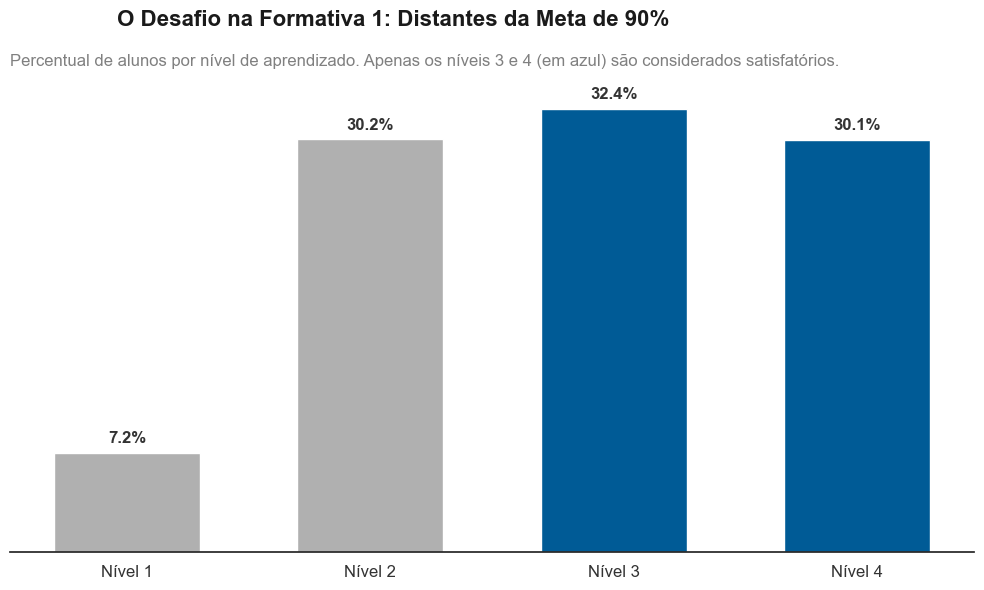

RESUMO EXECUTIVO:
-> 62.6% dos alfabetizandos atingiram os níveis 3 e 4 (Soma de 32.4% do N3 com 30.1% do N4).
-> Faltam 27.4 pontos percentuais para atingir a meta estipulada pelo programa (90%).


In [9]:
# Configurando o estilo do Seaborn para um visual limpo (sem fundo cinza ou grades)
sns.set_theme(style="white")

# CORREÇÃO: Utilizando a coluna '_resum' criada por você
df_plot = df_limpo.dropna(subset=['forma_1_result_resum']).copy()

# Calculando a porcentagem de alunos em cada nível usando a coluna correta
distribuicao = df_plot['forma_1_result_resum'].value_counts(normalize=True).sort_index() * 100

# Criando a figura e o eixo
fig, ax = plt.subplots(figsize=(10, 6))

# Definindo cores estratégicas (Storytelling): 
# Cinza para evidenciar o problema (Níveis 1 e 2), Azul para o sucesso (Níveis 3 e 4)
cores = ['#B0B0B0', '#B0B0B0', '#005b96', '#005b96']

# Plotando as barras
barras = ax.bar(distribuicao.index.astype(str), distribuicao.values, color=cores, width=0.6)

# Aplicando princípios de Storytelling com Dados
sns.despine(left=True, bottom=False)
ax.get_yaxis().set_visible(False)

# Adicionando os rótulos de dados diretamente no topo das barras
for barra in barras:
    altura = barra.get_height()
    # Verificação de segurança para não quebrar a anotação se a barra estiver vazia
    if pd.notnull(altura) and altura > 0:
        ax.annotate(f'{altura:.1f}%',
                    xy=(barra.get_x() + barra.get_width() / 2, altura),
                    xytext=(0, 5),  # Deslocamento vertical de 5 pontos
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=12, fontweight='bold', color='#333333')

# Configurando o eixo X para melhor legibilidade
ax.set_xticks(range(len(distribuicao.index)))
ax.set_xticklabels(['Nível 1', 'Nível 2', 'Nível 3', 'Nível 4'], fontsize=12, color='#333333')
ax.set_xlabel('')

# Título e Subtítulo orientados à narrativa (alinhados à esquerda)
plt.suptitle('O Desafio na Formativa 1: Distantes da Meta de 90%', fontsize=16, fontweight='bold', x=0.125, ha='left', color='#1a1a1a')
plt.title('Percentual de alunos por nível de aprendizado. Apenas os níveis 3 e 4 (em azul) são considerados satisfatórios.', fontsize=12, color='grey', loc='left', pad=15)

plt.tight_layout()
plt.show()

# Calculando e imprimindo o resumo consolidado com as categorias limpas
atingiram_meta = distribuicao.get('N3', 0) + distribuicao.get('N4', 0)

print("RESUMO EXECUTIVO:")
print(f"-> {atingiram_meta:.1f}% dos alfabetizandos atingiram os níveis 3 e 4 (Soma de {distribuicao.get('N3', 0):.1f}% do N3 com {distribuicao.get('N4', 0):.1f}% do N4).")
print(f"-> Faltam {90 - atingiram_meta:.1f} pontos percentuais para atingir a meta estipulada pelo programa (90%).")



## 3. Raio-X do Alfabetizando: Perfil de Entrada e Fator Socioemocional

Para entender o baixo atingimento da meta na Formativa 1, precisamos investigar quem são os alunos que estão com dificuldades. A metodologia está falhando para todos ou apenas para aqueles que chegaram com maiores defasagens? 

Nesta etapa, realizamos duas análises de correlação fundamentais:
1. **A Matriz de Evolução:** Comparamos o nível de entrada do aluno (Diagnóstica) com o resultado dele na Formativa 1.
2. **O Peso da Motivação:** Avaliamos como a atitude inicial do aluno (medida pelo Relatório Socioemocional) impacta diretamente a sua probabilidade de atingir os níveis satisfatórios (Níveis 3 e 4).


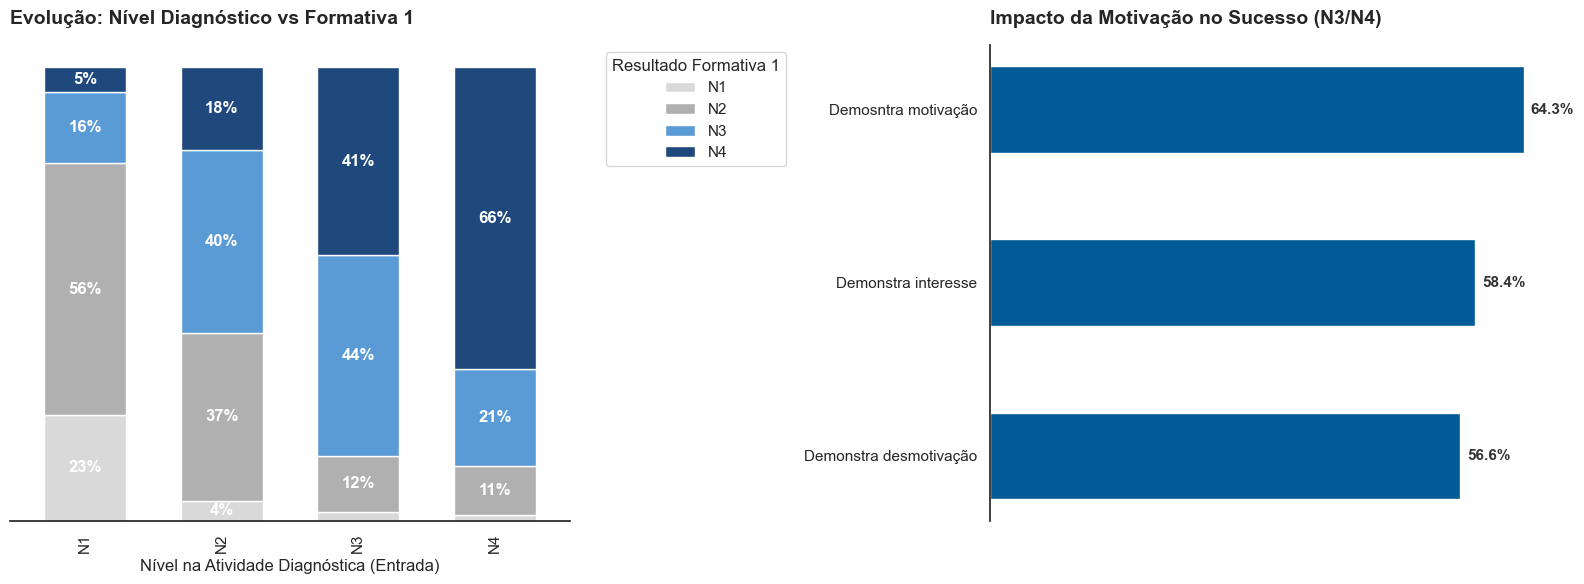

In [10]:
# Configuração visual padrão
sns.set_theme(style="white")

# 1. Preparação Otimizada dos Dados
# Filtrar nulos para a matriz Diagnóstica vs Formativa 1
df_diag = df_limpo.dropna(subset=['diag_entr_result_resum', 'forma_1_result_resum']).copy()
cross_diag = pd.crosstab(df_diag['diag_entr_result_resum'], df_diag['forma_1_result_resum'], normalize='index') * 100

# Calcular Taxa de Sucesso (N3 ou N4) baseada na Motivação Inicial
df_socio = df_limpo.dropna(subset=['socio_entr_q1_resum', 'forma_1_result_resum']).copy()
df_socio['sucesso_f1'] = df_socio['forma_1_result_resum'].isin(['N3', 'N4']).astype(int) * 100
sucesso_motivo = df_socio.groupby('socio_entr_q1_resum', observed=True)['sucesso_f1'].mean().sort_values()

# 2. Geração dos Gráficos (Matriz de Transição e Barras Horizontais)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: O peso do nível de entrada (Barras 100% Empilhadas)
cross_diag.plot(kind='bar', stacked=True, color=['#d9d9d9', '#b0b0b0', '#5b9bd5', '#1f497d'], ax=ax1, width=0.6)
sns.despine(ax=ax1, left=True)
ax1.get_yaxis().set_visible(False)
ax1.set_title('Evolução: Nível Diagnóstico vs Formativa 1', loc='left', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Nível na Atividade Diagnóstica (Entrada)', fontsize=12)
ax1.legend(title='Resultado Formativa 1', bbox_to_anchor=(1.05, 1), loc='upper left')

# Adicionando rótulos internos no Gráfico 1 (ocultando zeros e valores muito baixos para limpeza visual)
for c in ax1.containers:
    labels = [f'{w:.0f}%' if w > 4 else '' for w in c.datavalues]
    ax1.bar_label(c, labels=labels, label_type='center', color='white', fontweight='bold')

# Gráfico 2: O peso do comportamento (Motivação)
barras2 = ax2.barh(sucesso_motivo.index.astype(str), sucesso_motivo.values, color='#005b96', height=0.5)
sns.despine(ax=ax2, bottom=True)
ax2.get_xaxis().set_visible(False)
ax2.set_title('Impacto da Motivação no Sucesso (N3/N4)', loc='left', fontsize=14, fontweight='bold', pad=15)
ax2.set_ylabel('')

# Adicionando rótulos externos no Gráfico 2
for barra in barras2:
    largura = barra.get_width()
    ax2.annotate(f'{largura:.1f}%',
                 xy=(largura, barra.get_y() + barra.get_height() / 2),
                 xytext=(5, 0), textcoords="offset points",
                 ha='left', va='center', fontsize=11, fontweight='bold', color='#333333')

plt.tight_layout()
plt.show()


## 4. Fatores Logísticos, Geográficos e de Engajamento

O processo de alfabetização não ocorre no vácuo; ele é afetado pelo ambiente ao redor do aluno e do educador. Após compreendermos o perfil de entrada e a motivação, precisamos testar a influência de três variáveis operacionais:

1. **Localização (Urbana vs. Rural):** O contexto de infraestrutura e acesso influencia os resultados de aprendizagem?
2. **Frequência Específica (Unidade 1):** Qual o verdadeiro "custo" de uma falta? O engajamento físico nas aulas é um divisor de águas entre o sucesso e o baixo desempenho?
3. **Tamanho da Turma:** Existe um limite logístico de alunos em sala a partir do qual a metodologia perde eficácia, possivelmente devido à menor atenção individualizada do alfabetizador?

Abaixo, visualizamos essas três frentes de análise para compreender os gargalos operacionais do programa.


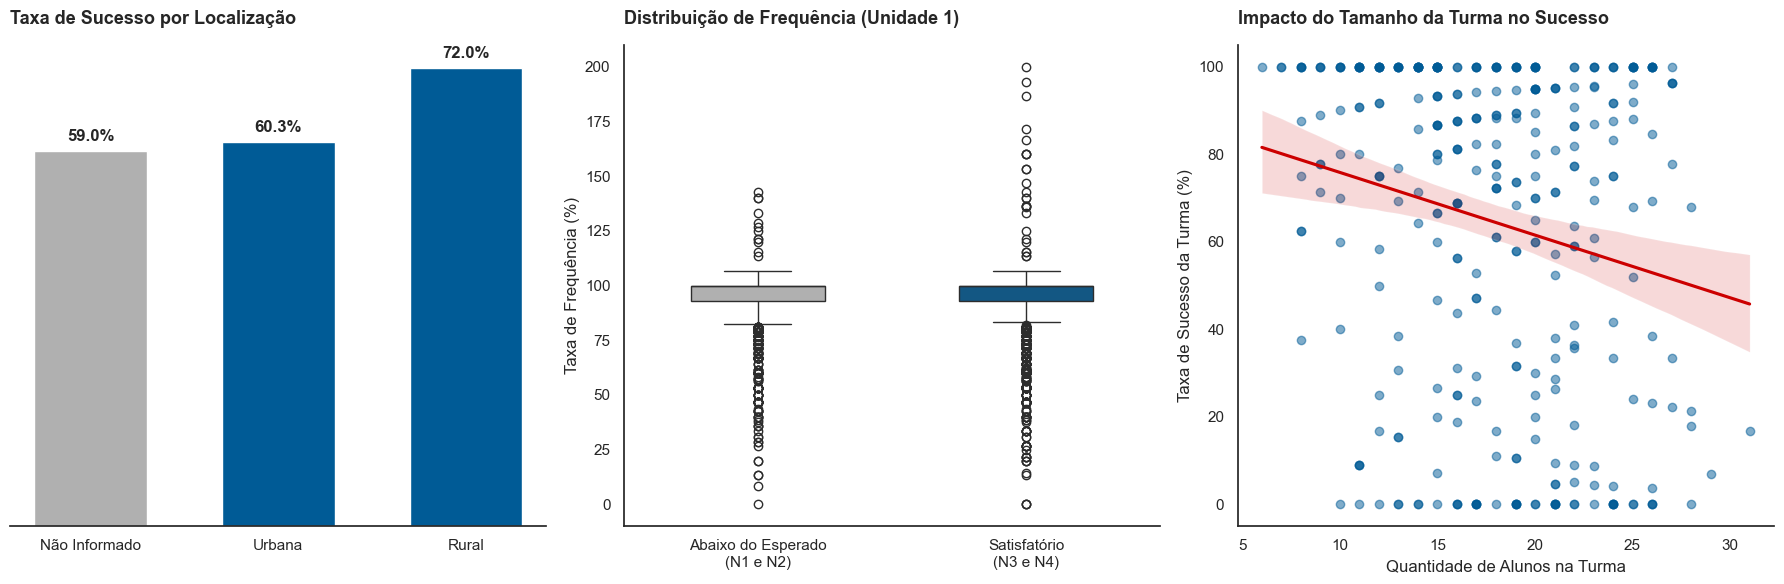

In [12]:
# Configuração visual padrão
sns.set_theme(style="white")

# 1. Preparação de Dados
# Filtrando apenas os que realizaram a Formativa 1 e criando a variável de sucesso binária
df_plot = df_limpo.dropna(subset=['forma_1_result_resum']).copy()
df_plot['sucesso_f1'] = df_plot['forma_1_result_resum'].isin(['N3', 'N4']).astype(int)
df_plot['taxa_freq_pct'] = df_plot['taxa_frequencia_unidade_1'] * 100

# 2. Configurando a Figura com 3 subgráficos (1 linha, 3 colunas)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# --- GRÁFICO 1: Fator Geográfico (Localização) ---
sucesso_loc = df_plot.groupby('ds_localizacao')['sucesso_f1'].mean().sort_values() * 100
# Destaque em azul para Rural e Urbana, e cinza para "Não Informado"
cores_loc = ['#b0b0b0' if loc == 'Não Informado' else '#005b96' for loc in sucesso_loc.index]

ax1.bar(sucesso_loc.index, sucesso_loc.values, color=cores_loc, width=0.6)
sns.despine(ax=ax1, left=True)
ax1.get_yaxis().set_visible(False)
ax1.set_title('Taxa de Sucesso por Localização', loc='left', fontsize=13, fontweight='bold', pad=15)

for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.1f}%', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')

# --- GRÁFICO 2: Engajamento (Frequência) ---
# Boxplot para mostrar a distribuição da frequência entre quem atingiu a meta e quem não atingiu
sns.boxplot(data=df_plot, x='sucesso_f1', y='taxa_freq_pct', palette=['#b0b0b0', '#005b96'], width=0.5, ax=ax2)
sns.despine(ax=ax2)
ax2.set_title('Distribuição de Frequência (Unidade 1)', loc='left', fontsize=13, fontweight='bold', pad=15)
ax2.set_xticks([0, 1])
ax2.set_xticklabels(['Abaixo do Esperado\n(N1 e N2)', 'Satisfatório\n(N3 e N4)'])
ax2.set_xlabel('')
ax2.set_ylabel('Taxa de Frequência (%)')

# --- GRÁFICO 3: Logística (Tamanho da Turma) ---
# Agrupando os dados por turma para ver a taxa de sucesso da turma inteira vs tamanho da sala
turmas_agg = df_plot.groupby('turma').agg(
    sucesso_rate=('sucesso_f1', lambda x: x.mean() * 100),
    tamanho_turma=('qtd_alfabetizandos', 'first')
).reset_index()

sns.regplot(data=turmas_agg, x='tamanho_turma', y='sucesso_rate', ax=ax3, 
            scatter_kws={'alpha': 0.5, 'color': '#005b96'}, line_kws={'color': '#cc0000'})
sns.despine(ax=ax3)
ax3.set_title('Impacto do Tamanho da Turma no Sucesso', loc='left', fontsize=13, fontweight='bold', pad=15)
ax3.set_xlabel('Quantidade de Alunos na Turma')
ax3.set_ylabel('Taxa de Sucesso da Turma (%)')

plt.tight_layout()
plt.show()
